In [1]:
"""
STEP 2: DATA ANALYSIS - Profile-based
=====================
Exploratory analysis of velocity profiles as whole entities.

PURPOSE:
- Understand how profile characteristics change with x-location
- Analyze effect of inlet conditions on profile shape

Analyses performed:
1. Profile Statistics Extraction
2. Streamwise Development (how profiles change with x)
3. PCA on Profile Features
4. t-SNE Clustering of Profiles
5. Mutual Information (what predicts profile characteristics)
6. Correlation Matrix
7. Conditional Entropy

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR 
import sys

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
from scipy.interpolate import interp1d
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [14]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_101.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform_1case.pkl'

OUTPUT_DIR = FIGURES_DIR

# Cube geometry
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075  # meters
X_CUBE_BACK = 0.090  # meters
X_RECOVERY = 0.20  # meters - approximate start of recovered flow

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

In [15]:
# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def interpolate_at_height(z, U_x, z_target):
    """Interpolate velocity at specific height"""
    if z_target < z.min() or z_target > z.max():
        return np.nan
    try:
        f = interp1d(z, U_x, kind='linear', fill_value='extrapolate')
        return float(f(z_target))
    except:
        return np.nan

def get_flow_regime(x_loc):
    """Determine flow regime based on x-location"""
    if x_loc < X_CUBE_FRONT:
        return 'upstream', 0
    elif x_loc <= X_CUBE_BACK:
        return 'over_cube', 1
    elif x_loc < X_RECOVERY:
        return 'wake', 2
    else:
        return 'far_downstream', 3

In [16]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\nLoading data from: {INPUT_FILE}")

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")



Loading data from: /home/vita/ML/DACI/Multi_Case_CFD/data/processed/all_cases_data_101.pkl
✓ Loaded 8 cases


In [17]:
# ============================================================================
# EXTRACT PROFILE STATISTICS
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING PROFILE STATISTICS")
print("="*80)
print("\nFor each of the 88 profiles, extracting:")
print("  • Basic statistics: U_max, U_min, U_mean, U_std")
print("  • Velocities at key heights: U_at_ground, U_at_H, U_at_2H")
print("  • Recirculation metrics: has_recirculation, recirculation_fraction")
print("  • Gradient at ground: dU_dz_ground")
print("  • Using inlet_type (categorical) instead of α, δ")

profile_rows = []

for case_id, case_data in all_cases_data.items():
    U_ref = case_data['U_ref']
    profile_type = case_data['profile_type']
    profile_name = case_data['profile_name']
    
    for x_loc, profile in case_data['profiles'].items():
        z = profile['z']
        U_x = profile['U_x']
        
        # Flow regime
        regime_name, regime_id = get_flow_regime(x_loc)
        
        # Basic statistics
        U_max = U_x.max()
        U_min = U_x.min()
        U_mean = U_x.mean()
        U_std = U_x.std()
        
        # Velocities at specific heights
        U_at_ground = U_x[0] if len(U_x) > 0 else np.nan
        U_at_H = interpolate_at_height(z, U_x, H_CUBE)
        U_at_2H = interpolate_at_height(z, U_x, 2*H_CUBE)
        U_at_3H = interpolate_at_height(z, U_x, 3*H_CUBE)
        
        # Recirculation detection
        has_recirculation = int(U_min < 0)
        n_negative = np.sum(U_x < 0)
        recirculation_fraction = n_negative / len(U_x)
        
        # Velocity gradient at ground
        if len(z) > 1 and (z[1] - z[0]) > 0:
            dU_dz_ground = (U_x[1] - U_x[0]) / (z[1] - z[0])
        else:
            dU_dz_ground = 0
        
        # Profile shape metrics
        U_range = U_max - U_min
        U_skewness = (U_mean - U_x[len(U_x)//2]) / U_std if U_std > 0 else 0  # Simple skewness proxy
        
        # Normalized metrics (by U_ref)
        U_mean_norm = U_mean / U_ref
        U_max_norm = U_max / U_ref
        U_at_H_norm = U_at_H / U_ref if not np.isnan(U_at_H) else np.nan
        
        profile_rows.append({
            # Identifiers
            'case_id': case_id,
            'x': x_loc,
            'x_norm': x_loc / H_CUBE,
            
            # Input features (what we use to predict)
            'U_ref': U_ref,
            'profile_type': profile_type,
            'profile_name': profile_name,
            'flow_regime': regime_id,
            'flow_regime_name': regime_name,
            
            # Profile statistics (what we analyze)
            'U_max': U_max,
            'U_min': U_min,
            'U_mean': U_mean,
            'U_std': U_std,
            'U_range': U_range,
            
            # Velocities at key heights
            'U_at_ground': U_at_ground,
            'U_at_H': U_at_H,
            'U_at_2H': U_at_2H,
            'U_at_3H': U_at_3H,
            
            # Recirculation
            'has_recirculation': has_recirculation,
            'recirculation_fraction': recirculation_fraction,
            
            # Gradients
            'dU_dz_ground': dU_dz_ground,
            
            # Normalized metrics
            'U_mean_norm': U_mean_norm,
            'U_max_norm': U_max_norm,
            'U_at_H_norm': U_at_H_norm,
            
            # Data quality
            'n_points': len(z),
            'z_min': z.min(),
            'z_max': z.max(),
        })

df_profiles = pd.DataFrame(profile_rows)

print(f"\n✓ Extracted statistics for {len(df_profiles)} profiles")
print(f"  Cases: {df_profiles['case_id'].nunique()}")
print(f"  X-locations: {df_profiles['x'].nunique()}")
print(f"  Profiles with recirculation: {df_profiles['has_recirculation'].sum()}")

print(f"\nFlow regime distribution:")
for regime in df_profiles['flow_regime_name'].unique():
    count = len(df_profiles[df_profiles['flow_regime_name'] == regime])
    print(f"  {regime:15s}: {count} profiles")

print(f"\nProfile statistics overview:")
print(df_profiles[['x_norm', 'U_ref', 'profile_name', 'U_mean', 'U_min', 'recirculation_fraction']].head(15))



EXTRACTING PROFILE STATISTICS

For each of the 88 profiles, extracting:
  • Basic statistics: U_max, U_min, U_mean, U_std
  • Velocities at key heights: U_at_ground, U_at_H, U_at_2H
  • Recirculation metrics: has_recirculation, recirculation_fraction
  • Gradient at ground: dU_dz_ground
  • Using inlet_type (categorical) instead of α, δ

✓ Extracted statistics for 808 profiles
  Cases: 8
  X-locations: 101
  Profiles with recirculation: 540

Flow regime distribution:
  upstream       : 240 profiles
  over_cube      : 160 profiles
  wake           : 352 profiles
  far_downstream : 56 profiles

Profile statistics overview:
      x_norm  U_ref profile_name    U_mean     U_min  recirculation_fraction
0   0.000000    1.0      Uniform  0.999888  0.978107                     0.0
1   0.250000    1.0      Uniform  1.000836  0.731537                     0.0
2   0.500000    1.0      Uniform  1.002054  0.465390                     0.0
3   0.750000    1.0      Uniform  1.003136  0.325020          


ANALYSIS 1a: STREAMWISE DEVELOPMENT OF PROFILES

How do profile statistics change with x-location?


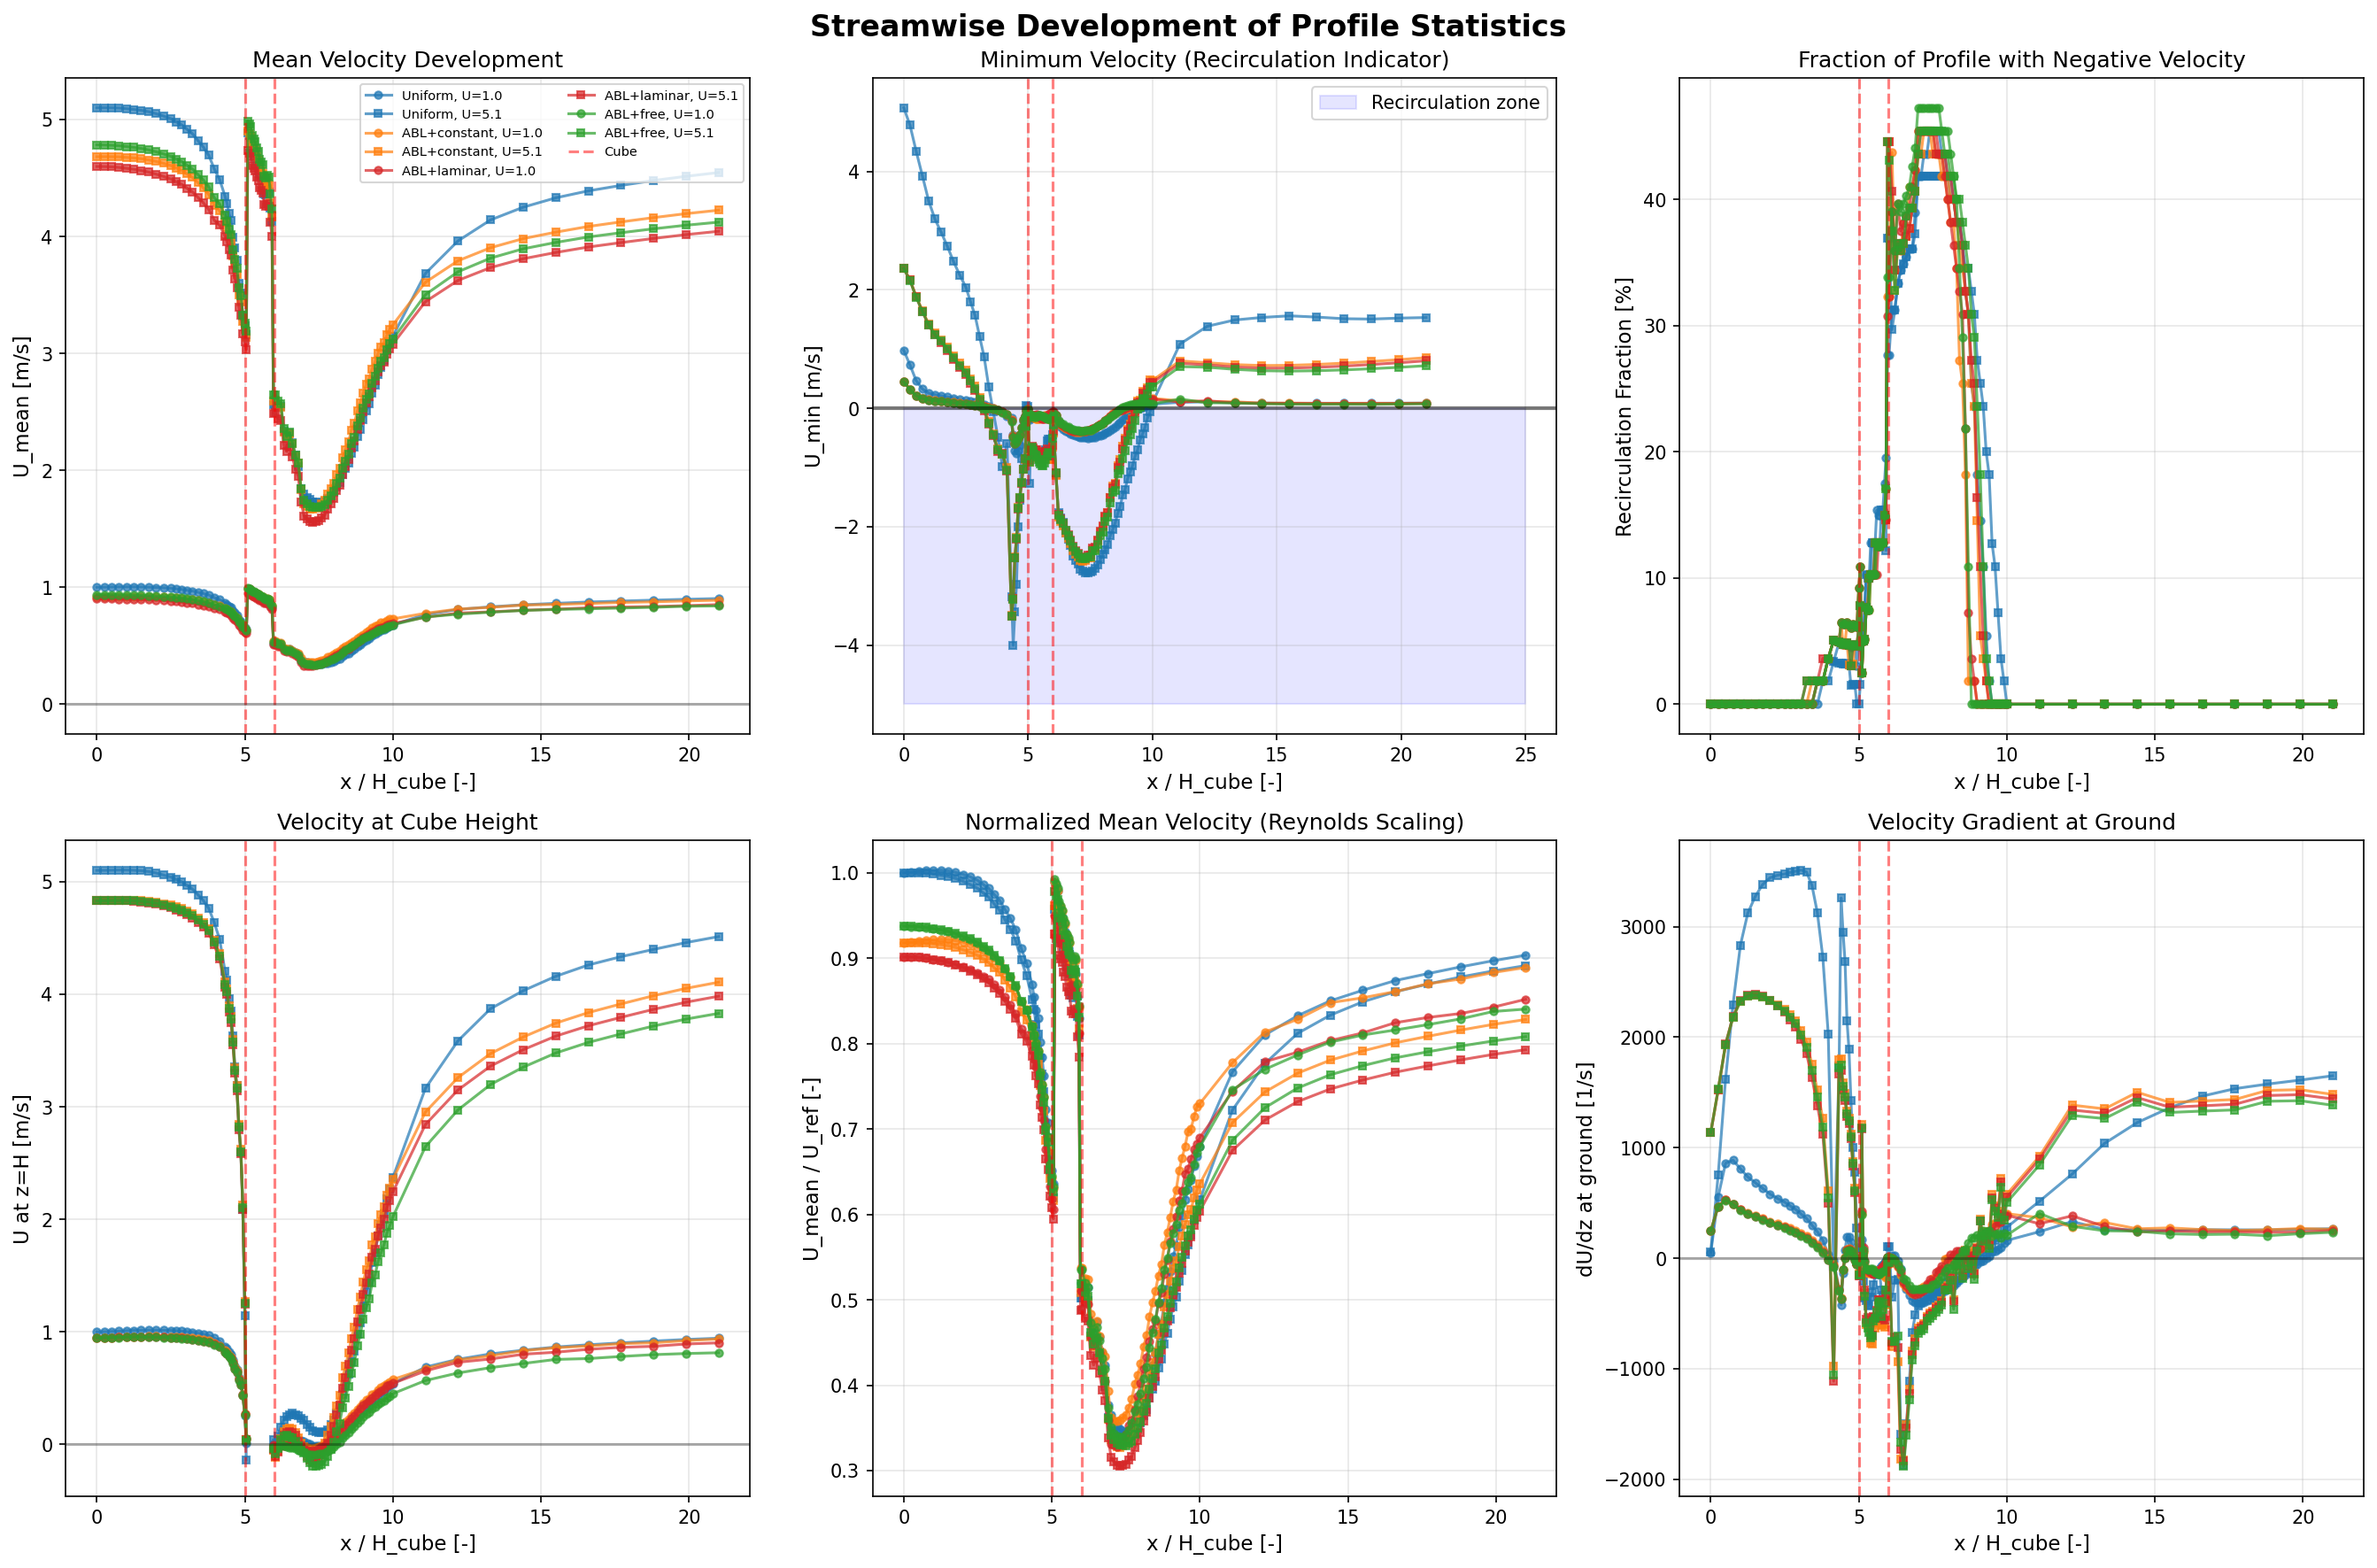

✓ Saved: step2_1a_profile_streamwise_development.png

📊 KEY OBSERVATIONS:
  • Wake region (6 < x/H < 13):
    - 266/352 profiles have recirculation
    - Max recirculation fraction: 47.3%
    - Most negative U_min: -2.79 m/s


In [18]:
# ============================================================================
# ANALYSIS 1a: STREAMWISE DEVELOPMENT
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 1a: STREAMWISE DEVELOPMENT OF PROFILES")
print("="*80)
print("\nHow do profile statistics change with x-location?")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Streamwise Development of Profile Statistics', fontsize=16, fontweight='bold')

# Color maps
profile_colors = {'Uniform': '#1f77b4', 'ABL+constant': '#ff7f0e', 'ABL+free': '#2ca02c', 'ABL+laminar': '#d62728'}
uref_markers = {1.0: 'o', 5.1: 's'}

# 1.1 U_mean vs x
ax = axes[0, 0]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        label = f'{pname}, U={u_ref}'
        ax.plot(subset['x_norm'], subset['U_mean'], 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7, label=label)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5, label='Cube')
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axhline(0, color='black', linestyle='-', alpha=0.3)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('U_mean [m/s]')
ax.set_title('Mean Velocity Development')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7, ncol=2)

# 1.2 U_min vs x (recirculation indicator)
ax = axes[0, 1]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        ax.plot(subset['x_norm'], subset['U_min'], 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axhline(0, color='black', linestyle='-', alpha=0.5, linewidth=2)
ax.fill_between([0, 25], [0, 0], [-5, -5], color='blue', alpha=0.1, label='Recirculation zone')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('U_min [m/s]')
ax.set_title('Minimum Velocity (Recirculation Indicator)')
ax.grid(True, alpha=0.3)
ax.legend()

# 1.3 Recirculation fraction vs x
ax = axes[0, 2]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        ax.plot(subset['x_norm'], subset['recirculation_fraction'] * 100, 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('Recirculation Fraction [%]')
ax.set_title('Fraction of Profile with Negative Velocity')
ax.grid(True, alpha=0.3)

# 1.4 U_at_H vs x (velocity at cube height)
ax = axes[1, 0]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        ax.plot(subset['x_norm'], subset['U_at_H'], 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axhline(0, color='black', linestyle='-', alpha=0.3)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('U at z=H [m/s]')
ax.set_title('Velocity at Cube Height')
ax.grid(True, alpha=0.3)

# 1.5 Normalized U_mean vs x
ax = axes[1, 1]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        ax.plot(subset['x_norm'], subset['U_mean_norm'], 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('U_mean / U_ref [-]')
ax.set_title('Normalized Mean Velocity (Reynolds Scaling)')
ax.grid(True, alpha=0.3)

# 1.6 Ground gradient vs x
ax = axes[1, 2]
for pname in df_profiles['profile_name'].unique():
    for u_ref in df_profiles['U_ref'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        subset = df_profiles[mask].sort_values('x_norm')
        ax.plot(subset['x_norm'], subset['dU_dz_ground'], 
                color=profile_colors.get(pname, 'gray'),
                marker=uref_markers.get(u_ref, 'o'),
                markersize=4, linewidth=1.5, alpha=0.7)

ax.axvline(X_CUBE_FRONT/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axvline(X_CUBE_BACK/H_CUBE, color='red', linestyle='--', alpha=0.5)
ax.axhline(0, color='black', linestyle='-', alpha=0.3)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('dU/dz at ground [1/s]')
ax.set_title('Velocity Gradient at Ground')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_1a_profile_streamwise_development.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_1a_profile_streamwise_development.png")
plt.close()

# Print key observations
print("\n📊 KEY OBSERVATIONS:")
wake_profiles = df_profiles[df_profiles['flow_regime_name'] == 'wake']
print(f"  • Wake region ({X_CUBE_BACK/H_CUBE:.0f} < x/H < {X_RECOVERY/H_CUBE:.0f}):")
print(f"    - {wake_profiles['has_recirculation'].sum()}/{len(wake_profiles)} profiles have recirculation")
print(f"    - Max recirculation fraction: {wake_profiles['recirculation_fraction'].max()*100:.1f}%")
print(f"    - Most negative U_min: {wake_profiles['U_min'].min():.2f} m/s")



ANALYSIS b: PROFILE STATISTICS BY INLET TYPE


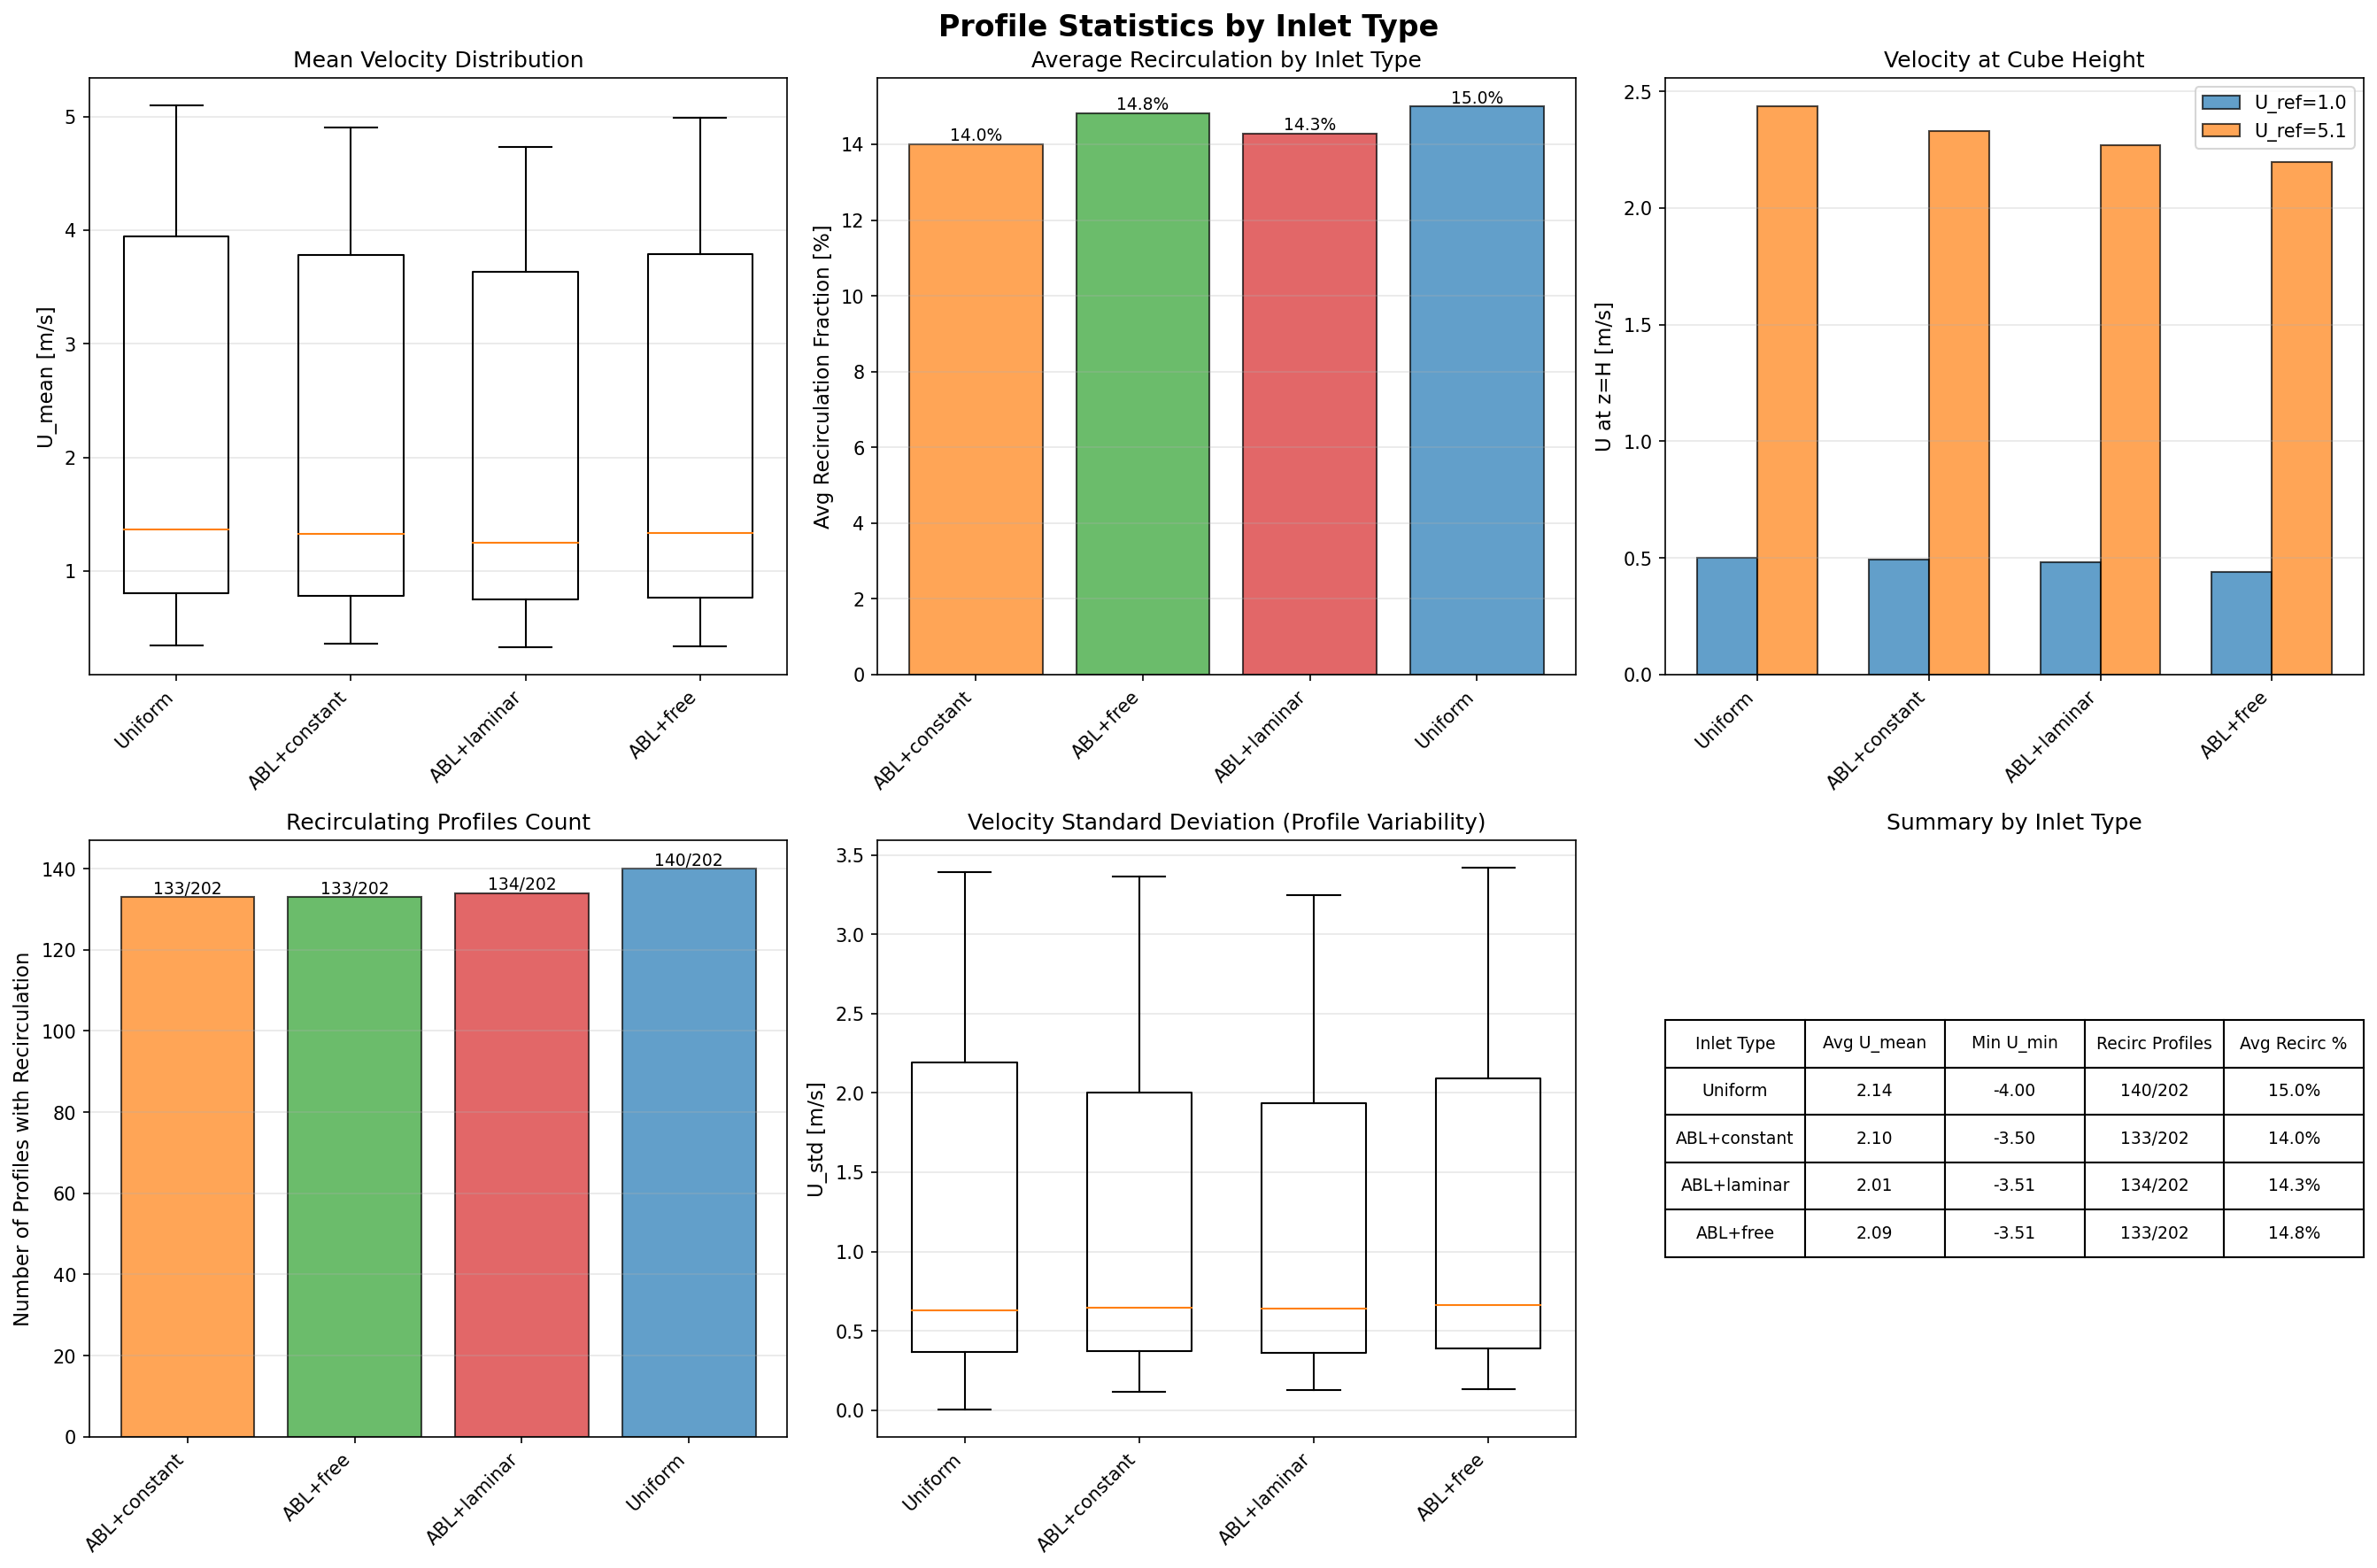

✓ Saved: step2_1b_profile_stats_by_inlet.png


In [19]:
# ============================================================================
# ANALYSIS 1b: PROFILE STATISTICS BY INLET TYPE
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS b: PROFILE STATISTICS BY INLET TYPE")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Profile Statistics by Inlet Type', fontsize=16, fontweight='bold')

# U_mean distribution by inlet type
ax = axes[0, 0]
for i, pname in enumerate(df_profiles['profile_name'].unique()):
    subset = df_profiles[df_profiles['profile_name'] == pname]['U_mean']
    ax.boxplot(subset, positions=[i], widths=0.6)
ax.set_xticks(range(len(df_profiles['profile_name'].unique())))
ax.set_xticklabels(df_profiles['profile_name'].unique(), rotation=45, ha='right')
ax.set_ylabel('U_mean [m/s]')
ax.set_title('Mean Velocity Distribution')
ax.grid(True, alpha=0.3, axis='y')

# Recirculation fraction by inlet type
ax = axes[0, 1]
recirc_by_type = df_profiles.groupby('profile_name')['recirculation_fraction'].mean() * 100
bars = ax.bar(range(len(recirc_by_type)), recirc_by_type.values, 
              color=[profile_colors.get(n, 'gray') for n in recirc_by_type.index],
              edgecolor='black', alpha=0.7)
ax.set_xticks(range(len(recirc_by_type)))
ax.set_xticklabels(recirc_by_type.index, rotation=45, ha='right')
ax.set_ylabel('Avg Recirculation Fraction [%]')
ax.set_title('Average Recirculation by Inlet Type')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}%', 
            ha='center', va='bottom', fontsize=9)

# U_at_H by inlet type and U_ref
ax = axes[0, 2]
x_pos = np.arange(len(df_profiles['profile_name'].unique()))
width = 0.35
for i, u_ref in enumerate([1.0, 5.1]):
    means = []
    for pname in df_profiles['profile_name'].unique():
        mask = (df_profiles['profile_name'] == pname) & (df_profiles['U_ref'] == u_ref)
        means.append(df_profiles[mask]['U_at_H'].mean())
    ax.bar(x_pos + i*width, means, width, label=f'U_ref={u_ref}', alpha=0.7, edgecolor='black')

ax.set_xticks(x_pos + width/2)
ax.set_xticklabels(df_profiles['profile_name'].unique(), rotation=45, ha='right')
ax.set_ylabel('U at z=H [m/s]')
ax.set_title('Velocity at Cube Height')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Number of recirculating profiles by inlet type
ax = axes[1, 0]
recirc_count = df_profiles.groupby('profile_name')['has_recirculation'].sum()
total_count = df_profiles.groupby('profile_name').size()
bars = ax.bar(range(len(recirc_count)), recirc_count.values,
              color=[profile_colors.get(n, 'gray') for n in recirc_count.index],
              edgecolor='black', alpha=0.7)
ax.set_xticks(range(len(recirc_count)))
ax.set_xticklabels(recirc_count.index, rotation=45, ha='right')
ax.set_ylabel('Number of Profiles with Recirculation')
ax.set_title('Recirculating Profiles Count')
ax.grid(True, alpha=0.3, axis='y')
for i, bar in enumerate(bars):
    height = bar.get_height()
    total = total_count.values[i]
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{int(height)}/{total}', 
            ha='center', va='bottom', fontsize=9)

# U_std by inlet type (profile variability)
ax = axes[1, 1]
for i, pname in enumerate(df_profiles['profile_name'].unique()):
    subset = df_profiles[df_profiles['profile_name'] == pname]['U_std']
    ax.boxplot(subset, positions=[i], widths=0.6)
ax.set_xticks(range(len(df_profiles['profile_name'].unique())))
ax.set_xticklabels(df_profiles['profile_name'].unique(), rotation=45, ha='right')
ax.set_ylabel('U_std [m/s]')
ax.set_title('Velocity Standard Deviation (Profile Variability)')
ax.grid(True, alpha=0.3, axis='y')

# Summary statistics table
ax = axes[1, 2]
summary_data = []
for pname in df_profiles['profile_name'].unique():
    subset = df_profiles[df_profiles['profile_name'] == pname]
    summary_data.append([
        pname,
        f"{subset['U_mean'].mean():.2f}",
        f"{subset['U_min'].min():.2f}",
        f"{subset['has_recirculation'].sum()}/{len(subset)}",
        f"{subset['recirculation_fraction'].mean()*100:.1f}%"
    ])

table = ax.table(cellText=summary_data,
                colLabels=['Inlet Type', 'Avg U_mean', 'Min U_min', 'Recirc Profiles', 'Avg Recirc %'],
                cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)
ax.axis('off')
ax.set_title('Summary by Inlet Type')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_1b_profile_stats_by_inlet.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_1b_profile_stats_by_inlet.png")
plt.close()


ANALYSIS 3: PCA ON PROFILE STATISTICS
  Using 672 profiles
  Features: ['x_norm', 'U_ref', 'profile_type', 'U_mean', 'U_std', 'U_at_H', 'recirculation_fraction']

PCA Results:
  PC1: 40.01%
  PC2: 27.37%
  PC3: 14.29%
  PC4: 14.11%
  Cumulative (PC1+PC2): 67.4%


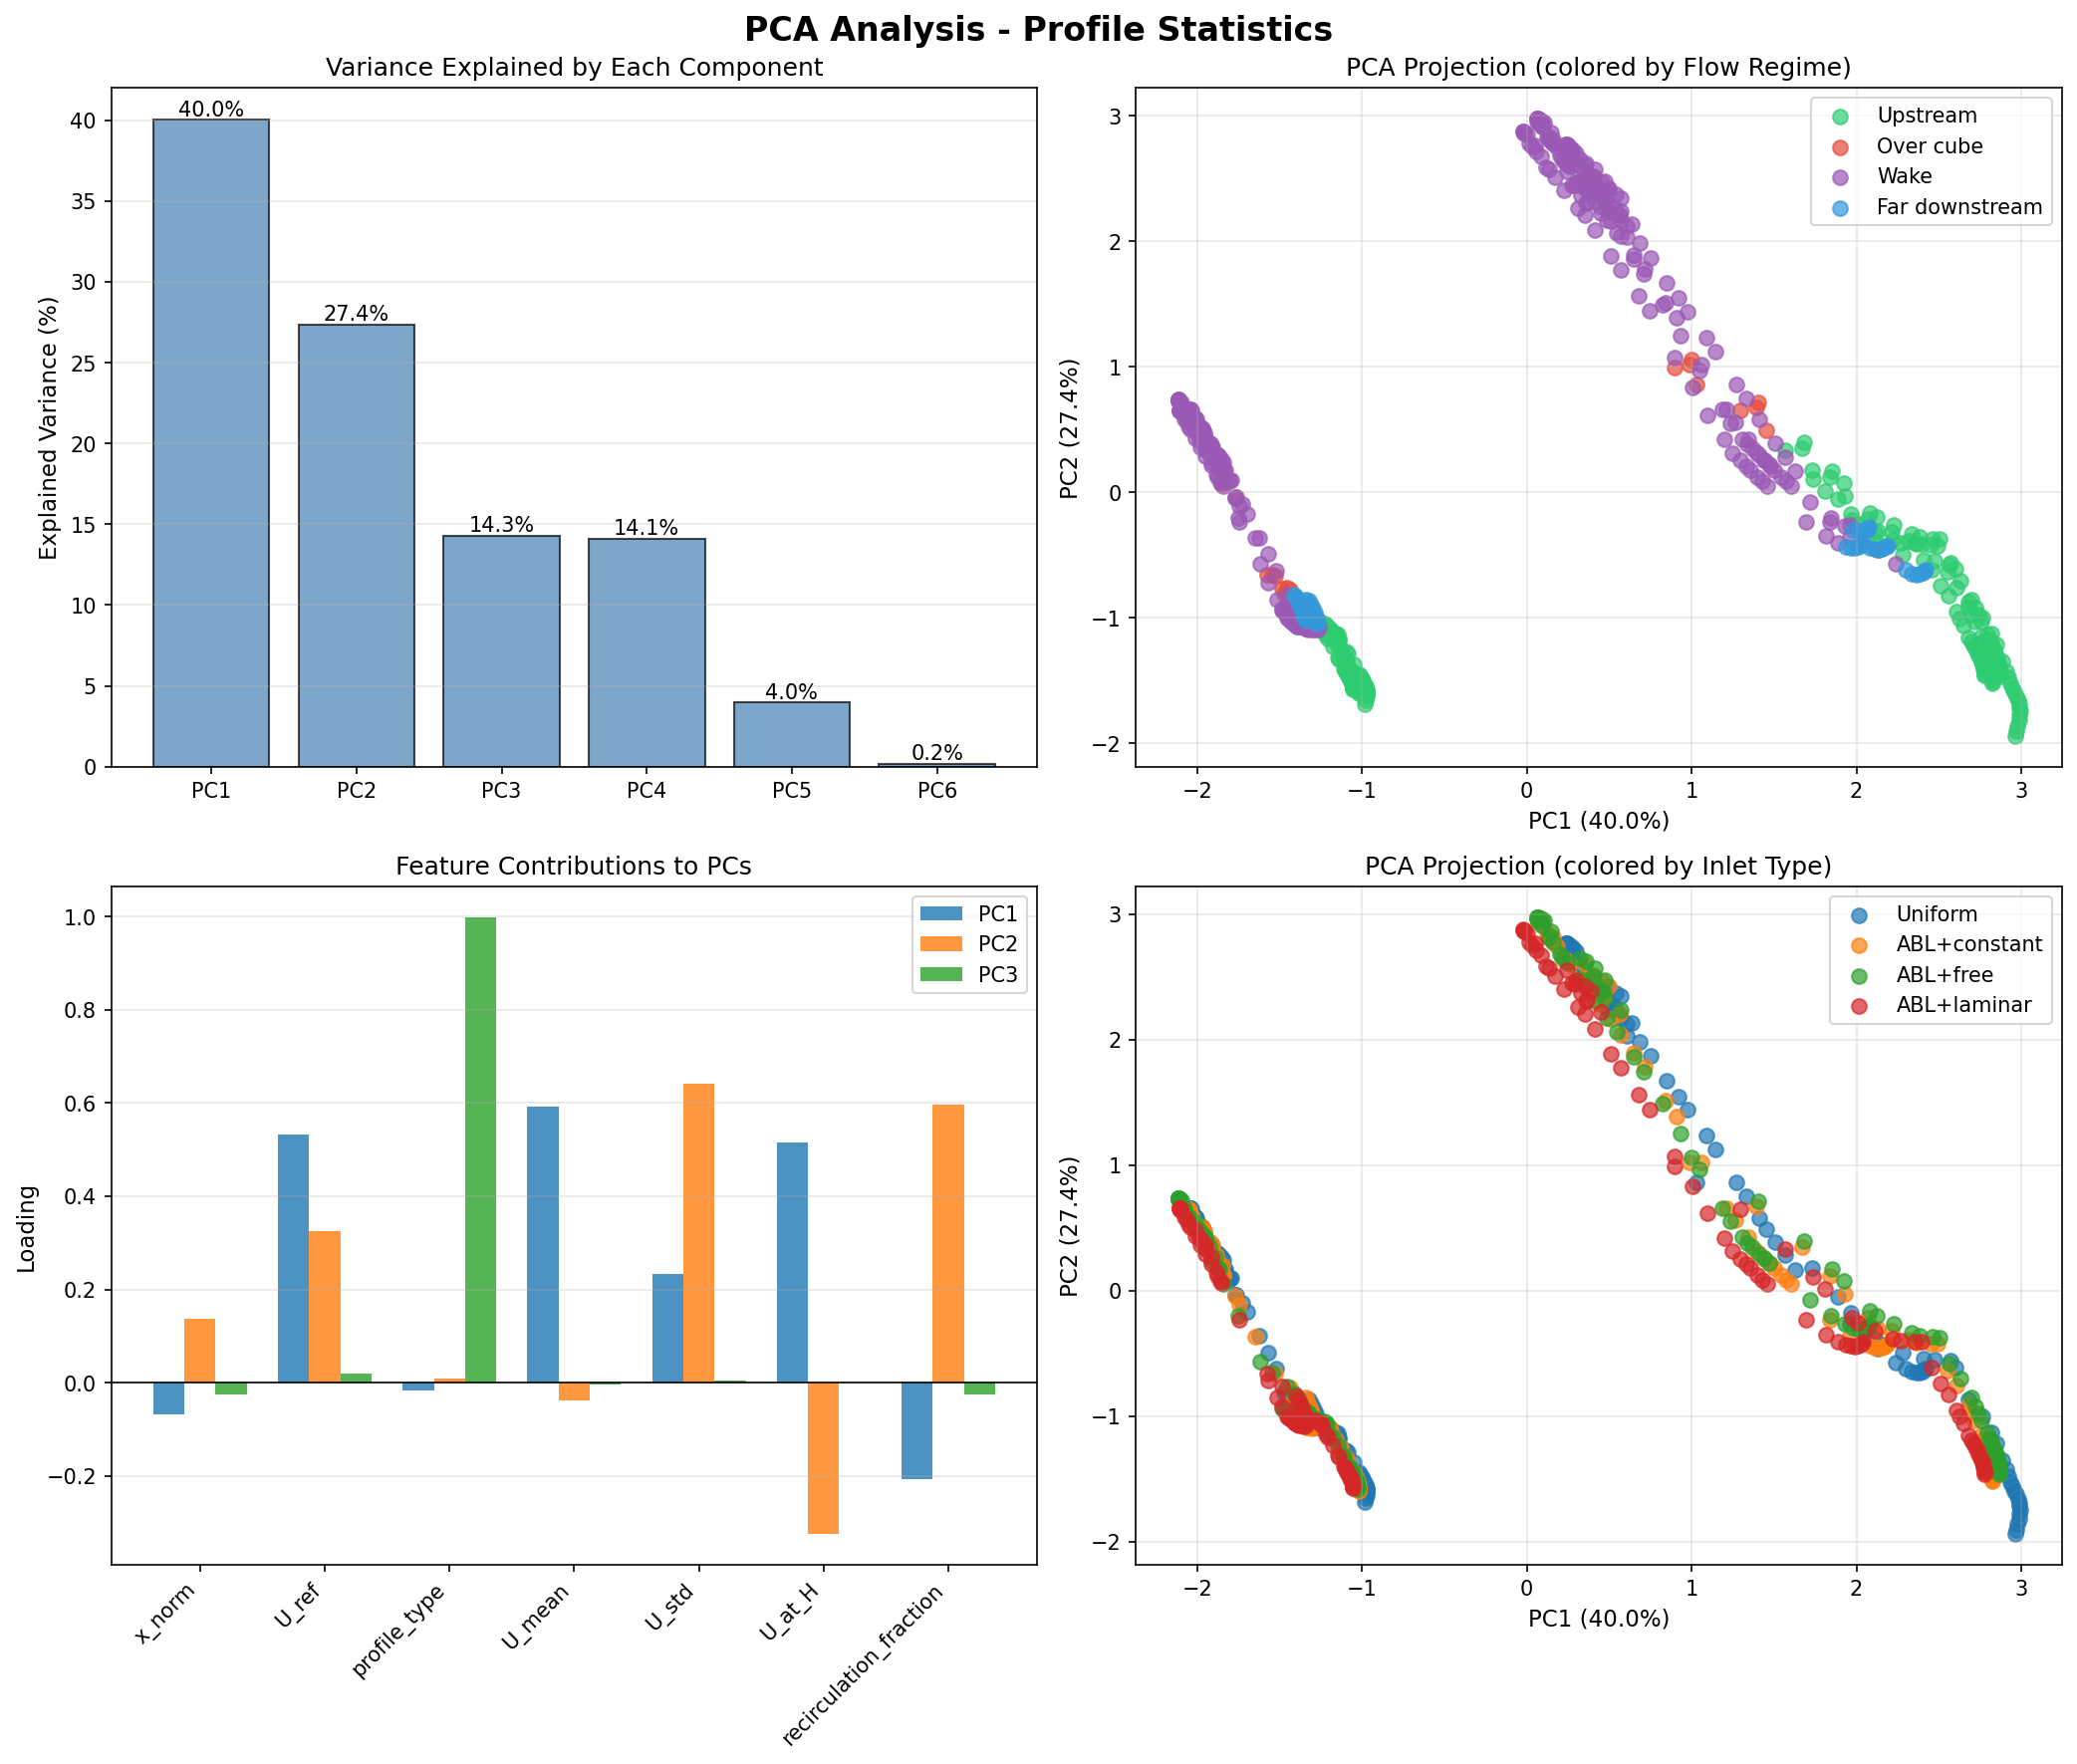

✓ Saved: step2_2_profile_pca.png


In [20]:
# ============================================================================
# ANALYSIS 2: PCA ON PROFILE STATISTICS
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 3: PCA ON PROFILE STATISTICS")
print("="*80)

# Select features for PCA
feature_cols = ['x_norm', 'U_ref', 'profile_type', 
                'U_mean', 'U_std', 'U_at_H', 'recirculation_fraction']

df_pca = df_profiles[feature_cols].dropna()
print(f"  Using {len(df_pca)} profiles")
print(f"  Features: {feature_cols}")

# Standardize
scaler = StandardScaler()
features_scaled = scaler.fit_transform(df_pca.values)

# PCA
pca = PCA(n_components=min(len(feature_cols), len(df_pca)))
pca_result = pca.fit_transform(features_scaled)

print(f"\nPCA Results:")
for i, var in enumerate(pca.explained_variance_ratio_[:4]):
    print(f"  PC{i+1}: {var*100:.2f}%")
print(f"  Cumulative (PC1+PC2): {sum(pca.explained_variance_ratio_[:2])*100:.1f}%")

# Create PCA plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('PCA Analysis - Profile Statistics', fontsize=16, fontweight='bold')

# Explained variance
ax = axes[0, 0]
n_show = min(6, len(pca.explained_variance_ratio_))
pc_labels = [f'PC{i+1}' for i in range(n_show)]
bars = ax.bar(pc_labels, pca.explained_variance_ratio_[:n_show] * 100,
              edgecolor='black', alpha=0.7, color='steelblue')
ax.set_ylabel('Explained Variance (%)')
ax.set_title('Variance Explained by Each Component')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}%', ha='center', va='bottom')

# PCA projection colored by flow regime
ax = axes[0, 1]
regime_colors_map = {0: '#2ecc71', 1: '#e74c3c', 2: '#9b59b6', 3: '#3498db'}
regime_names_map = {0: 'Upstream', 1: 'Over cube', 2: 'Wake', 3: 'Far downstream'}
flow_regimes = df_profiles.loc[df_pca.index, 'flow_regime'].values

for regime in np.unique(flow_regimes):
    mask = flow_regimes == regime
    ax.scatter(pca_result[mask, 0], pca_result[mask, 1],
               c=regime_colors_map[regime], s=50, alpha=0.7,
               label=regime_names_map[regime])

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('PCA Projection (colored by Flow Regime)')
ax.legend()
ax.grid(True, alpha=0.3)

# Feature loadings
ax = axes[1, 0]
n_pcs_show = min(3, pca.components_.shape[0])
x_pos = np.arange(len(feature_cols))
width = 0.25

for i in range(n_pcs_show):
    offset = (i - 1) * width
    ax.bar(x_pos + offset, pca.components_[i], width,
           label=f'PC{i+1}', alpha=0.8)

ax.set_ylabel('Loading')
ax.set_title('Feature Contributions to PCs')
ax.set_xticks(x_pos)
ax.set_xticklabels(feature_cols, rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# PCA projection colored by inlet type
ax = axes[1, 1]
profile_types_pca = df_profiles.loc[df_pca.index, 'profile_type'].values
profile_names_pca = df_profiles.loc[df_pca.index, 'profile_name'].values

for ptype in np.unique(profile_types_pca):
    mask = profile_types_pca == ptype
    pname = df_profiles[df_profiles['profile_type'] == ptype]['profile_name'].iloc[0]
    ax.scatter(pca_result[mask, 0], pca_result[mask, 1],
               c=profile_colors.get(pname, 'gray'), s=50, alpha=0.7,
               label=pname)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('PCA Projection (colored by Inlet Type)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_2_profile_pca.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_2_profile_pca.png")
plt.close()


ANALYSIS 3: t-SNE CLUSTERING OF PROFILES

Running t-SNE on 672 profiles...
✓ t-SNE complete


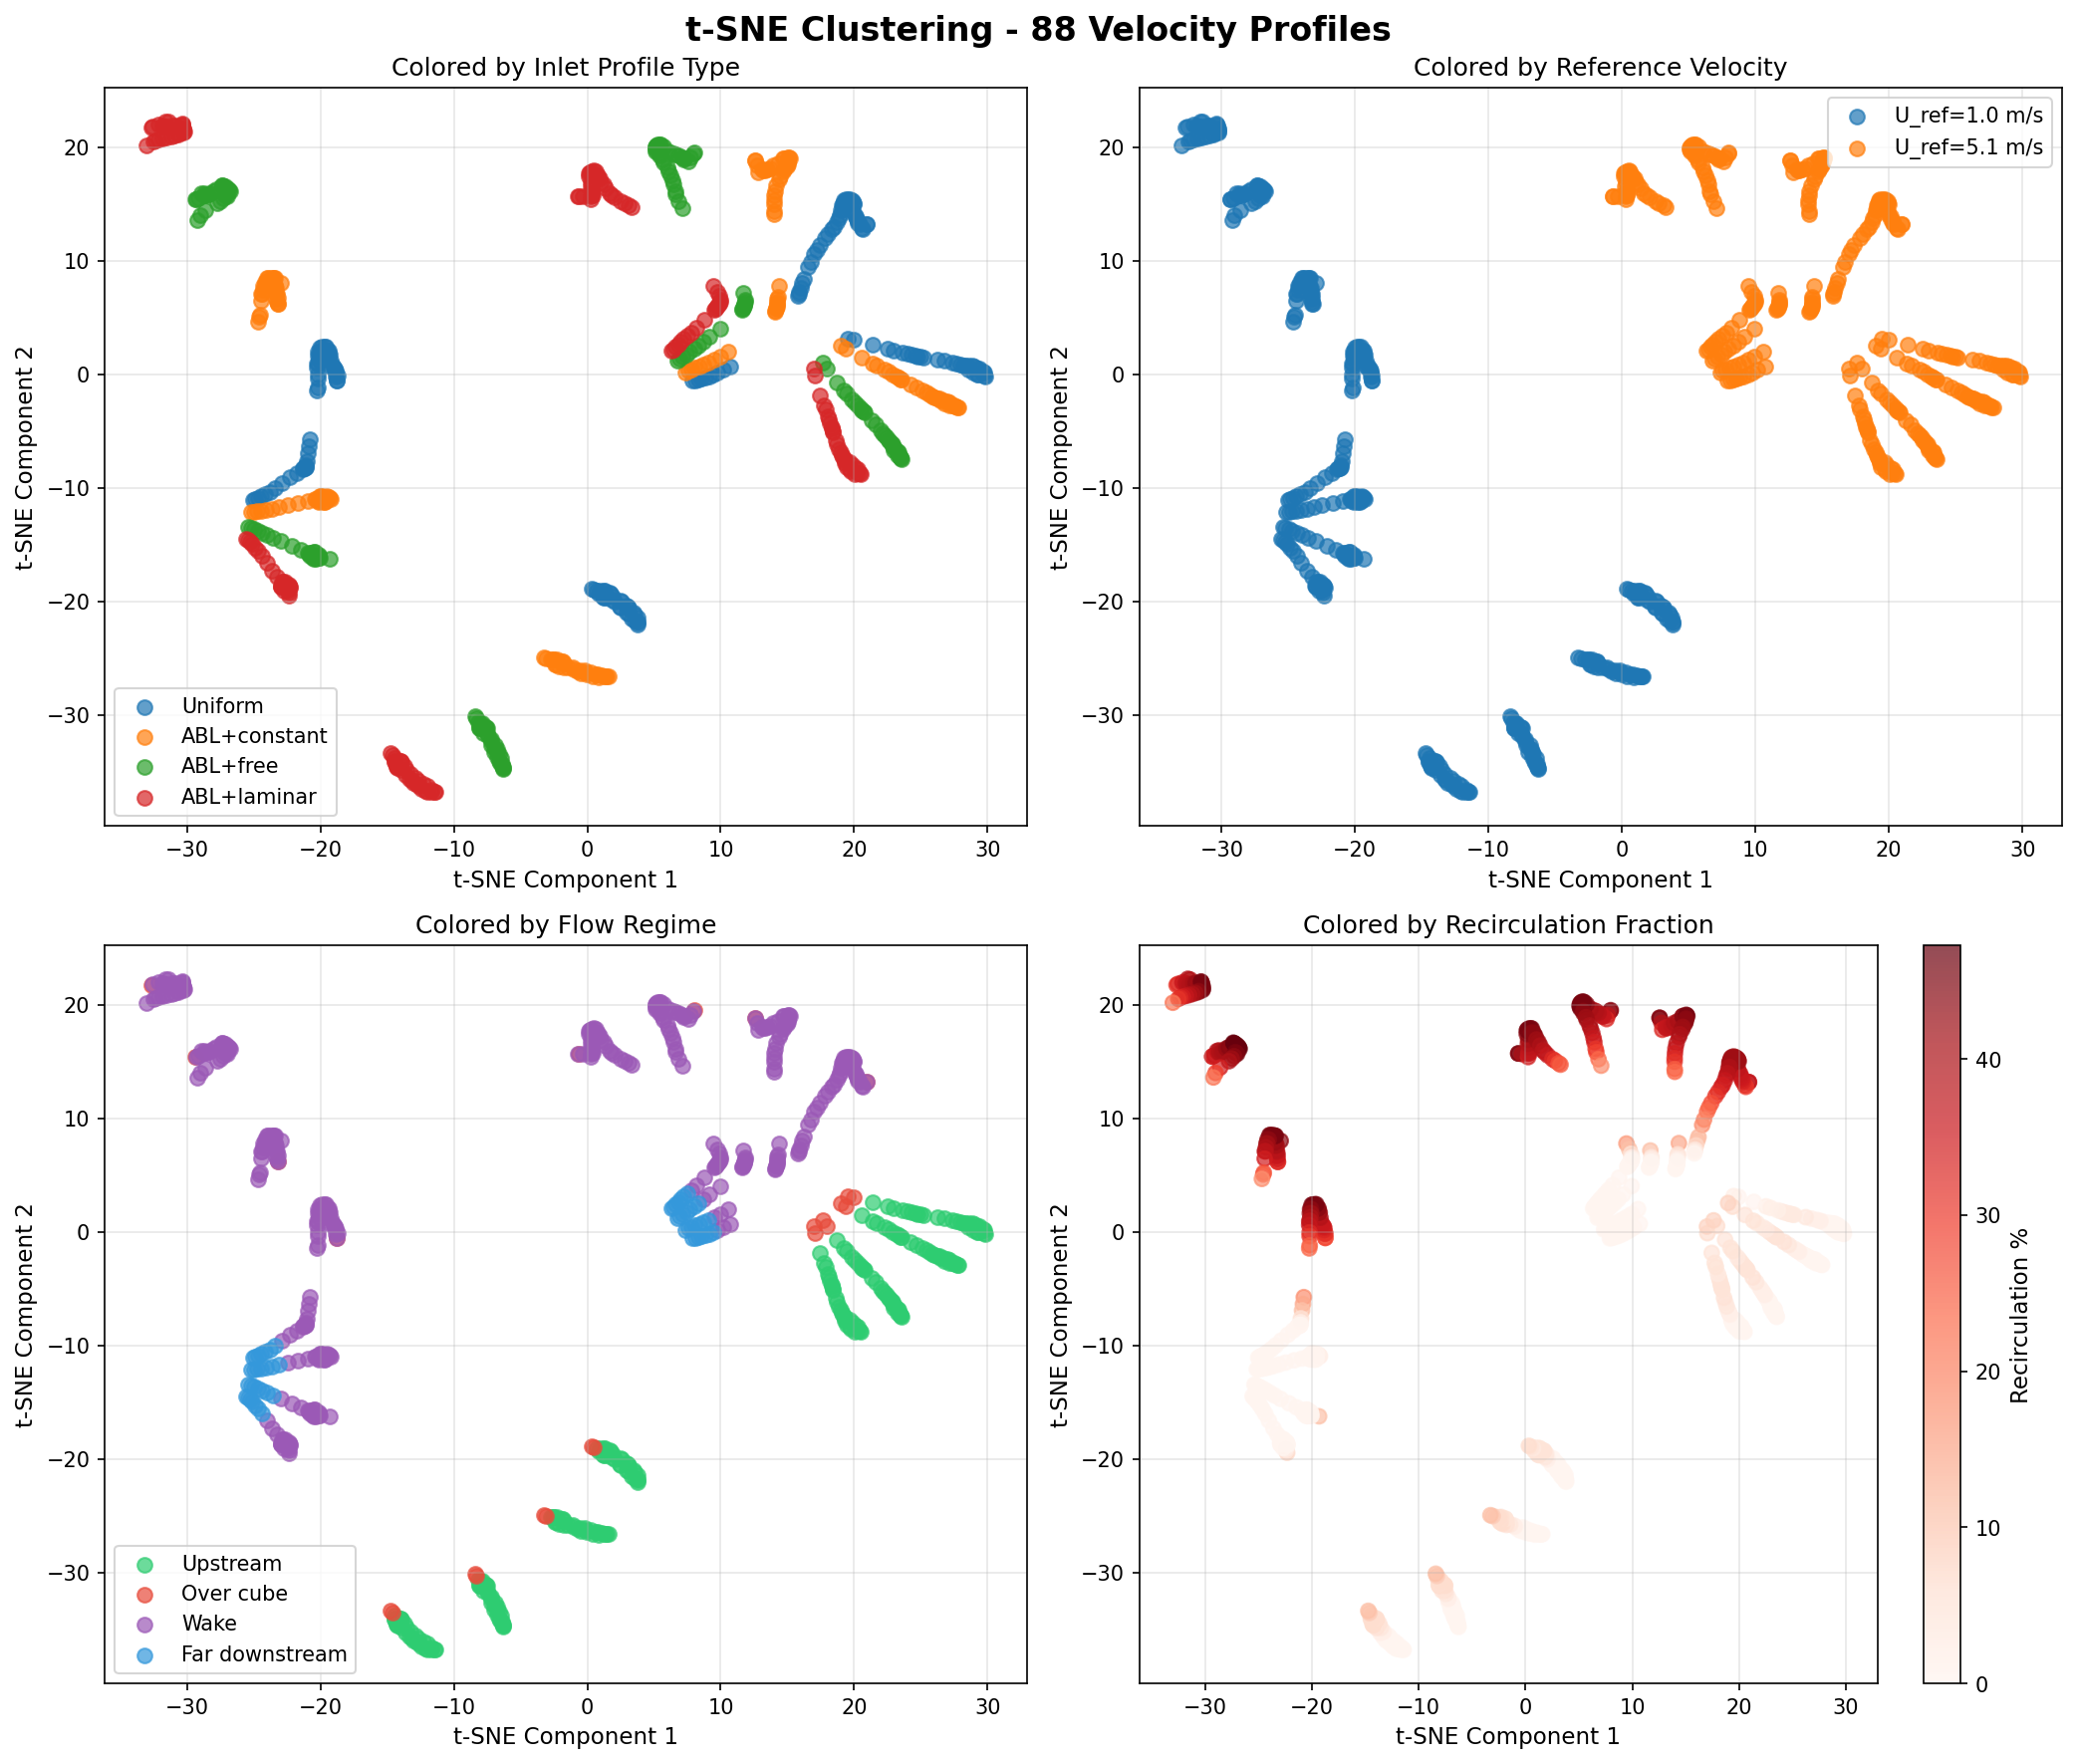

✓ Saved: step2_3_profile_tsne.png


In [21]:
# ============================================================================
# ANALYSIS 3: t-SNE CLUSTERING OF PROFILES
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 3: t-SNE CLUSTERING OF PROFILES")
print("="*80)

print(f"\nRunning t-SNE on {len(df_pca)} profiles...")

tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(df_pca)//4), max_iter=1000)
tsne_result = tsne.fit_transform(features_scaled)

print("✓ t-SNE complete")

# Create t-SNE plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('t-SNE Clustering - 88 Velocity Profiles', fontsize=16, fontweight='bold')

# Colored by inlet type
ax = axes[0, 0]
for ptype in np.unique(profile_types_pca):
    mask = profile_types_pca == ptype
    pname = df_profiles[df_profiles['profile_type'] == ptype]['profile_name'].iloc[0]
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1],
               c=profile_colors.get(pname, 'gray'), s=50, alpha=0.7,
               label=pname)

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Inlet Profile Type')
ax.legend()
ax.grid(True, alpha=0.3)

# Colored by U_ref
ax = axes[0, 1]
u_refs_pca = df_profiles.loc[df_pca.index, 'U_ref'].values
for u_ref in np.unique(u_refs_pca):
    mask = u_refs_pca == u_ref
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1],
               s=50, alpha=0.7, label=f'U_ref={u_ref:.1f} m/s')

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Reference Velocity')
ax.legend()
ax.grid(True, alpha=0.3)

# Colored by flow regime
ax = axes[1, 0]
for regime in np.unique(flow_regimes):
    mask = flow_regimes == regime
    ax.scatter(tsne_result[mask, 0], tsne_result[mask, 1],
               c=regime_colors_map[regime], s=50, alpha=0.7,
               label=regime_names_map[regime])

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Flow Regime')
ax.legend()
ax.grid(True, alpha=0.3)

# Colored by recirculation fraction
ax = axes[1, 1]
recirc_fracs = df_profiles.loc[df_pca.index, 'recirculation_fraction'].values
scatter = ax.scatter(tsne_result[:, 0], tsne_result[:, 1],
                     c=recirc_fracs * 100, s=50, alpha=0.7, cmap='Reds')
ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_title('Colored by Recirculation Fraction')
plt.colorbar(scatter, ax=ax, label='Recirculation %')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_3_profile_tsne.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_3_profile_tsne.png")
plt.close()


ANALYSIS 4: MUTUAL INFORMATION - PROFILE STATISTICS

What predicts profile characteristics?
  Input features: x_norm, U_ref, profile_type
  Target: various profile statistics

Mutual Information Results:
Target                    x_norm       U_ref        profile_type
------------------------------------------------------------
U_mean                    1.7469       0.6938       0.0053
U_at_H                    1.6516       0.3756       0.0172
recirculation_fraction    1.9337       0.0488       0.0000
U_std                     1.5989       0.5738       0.0000


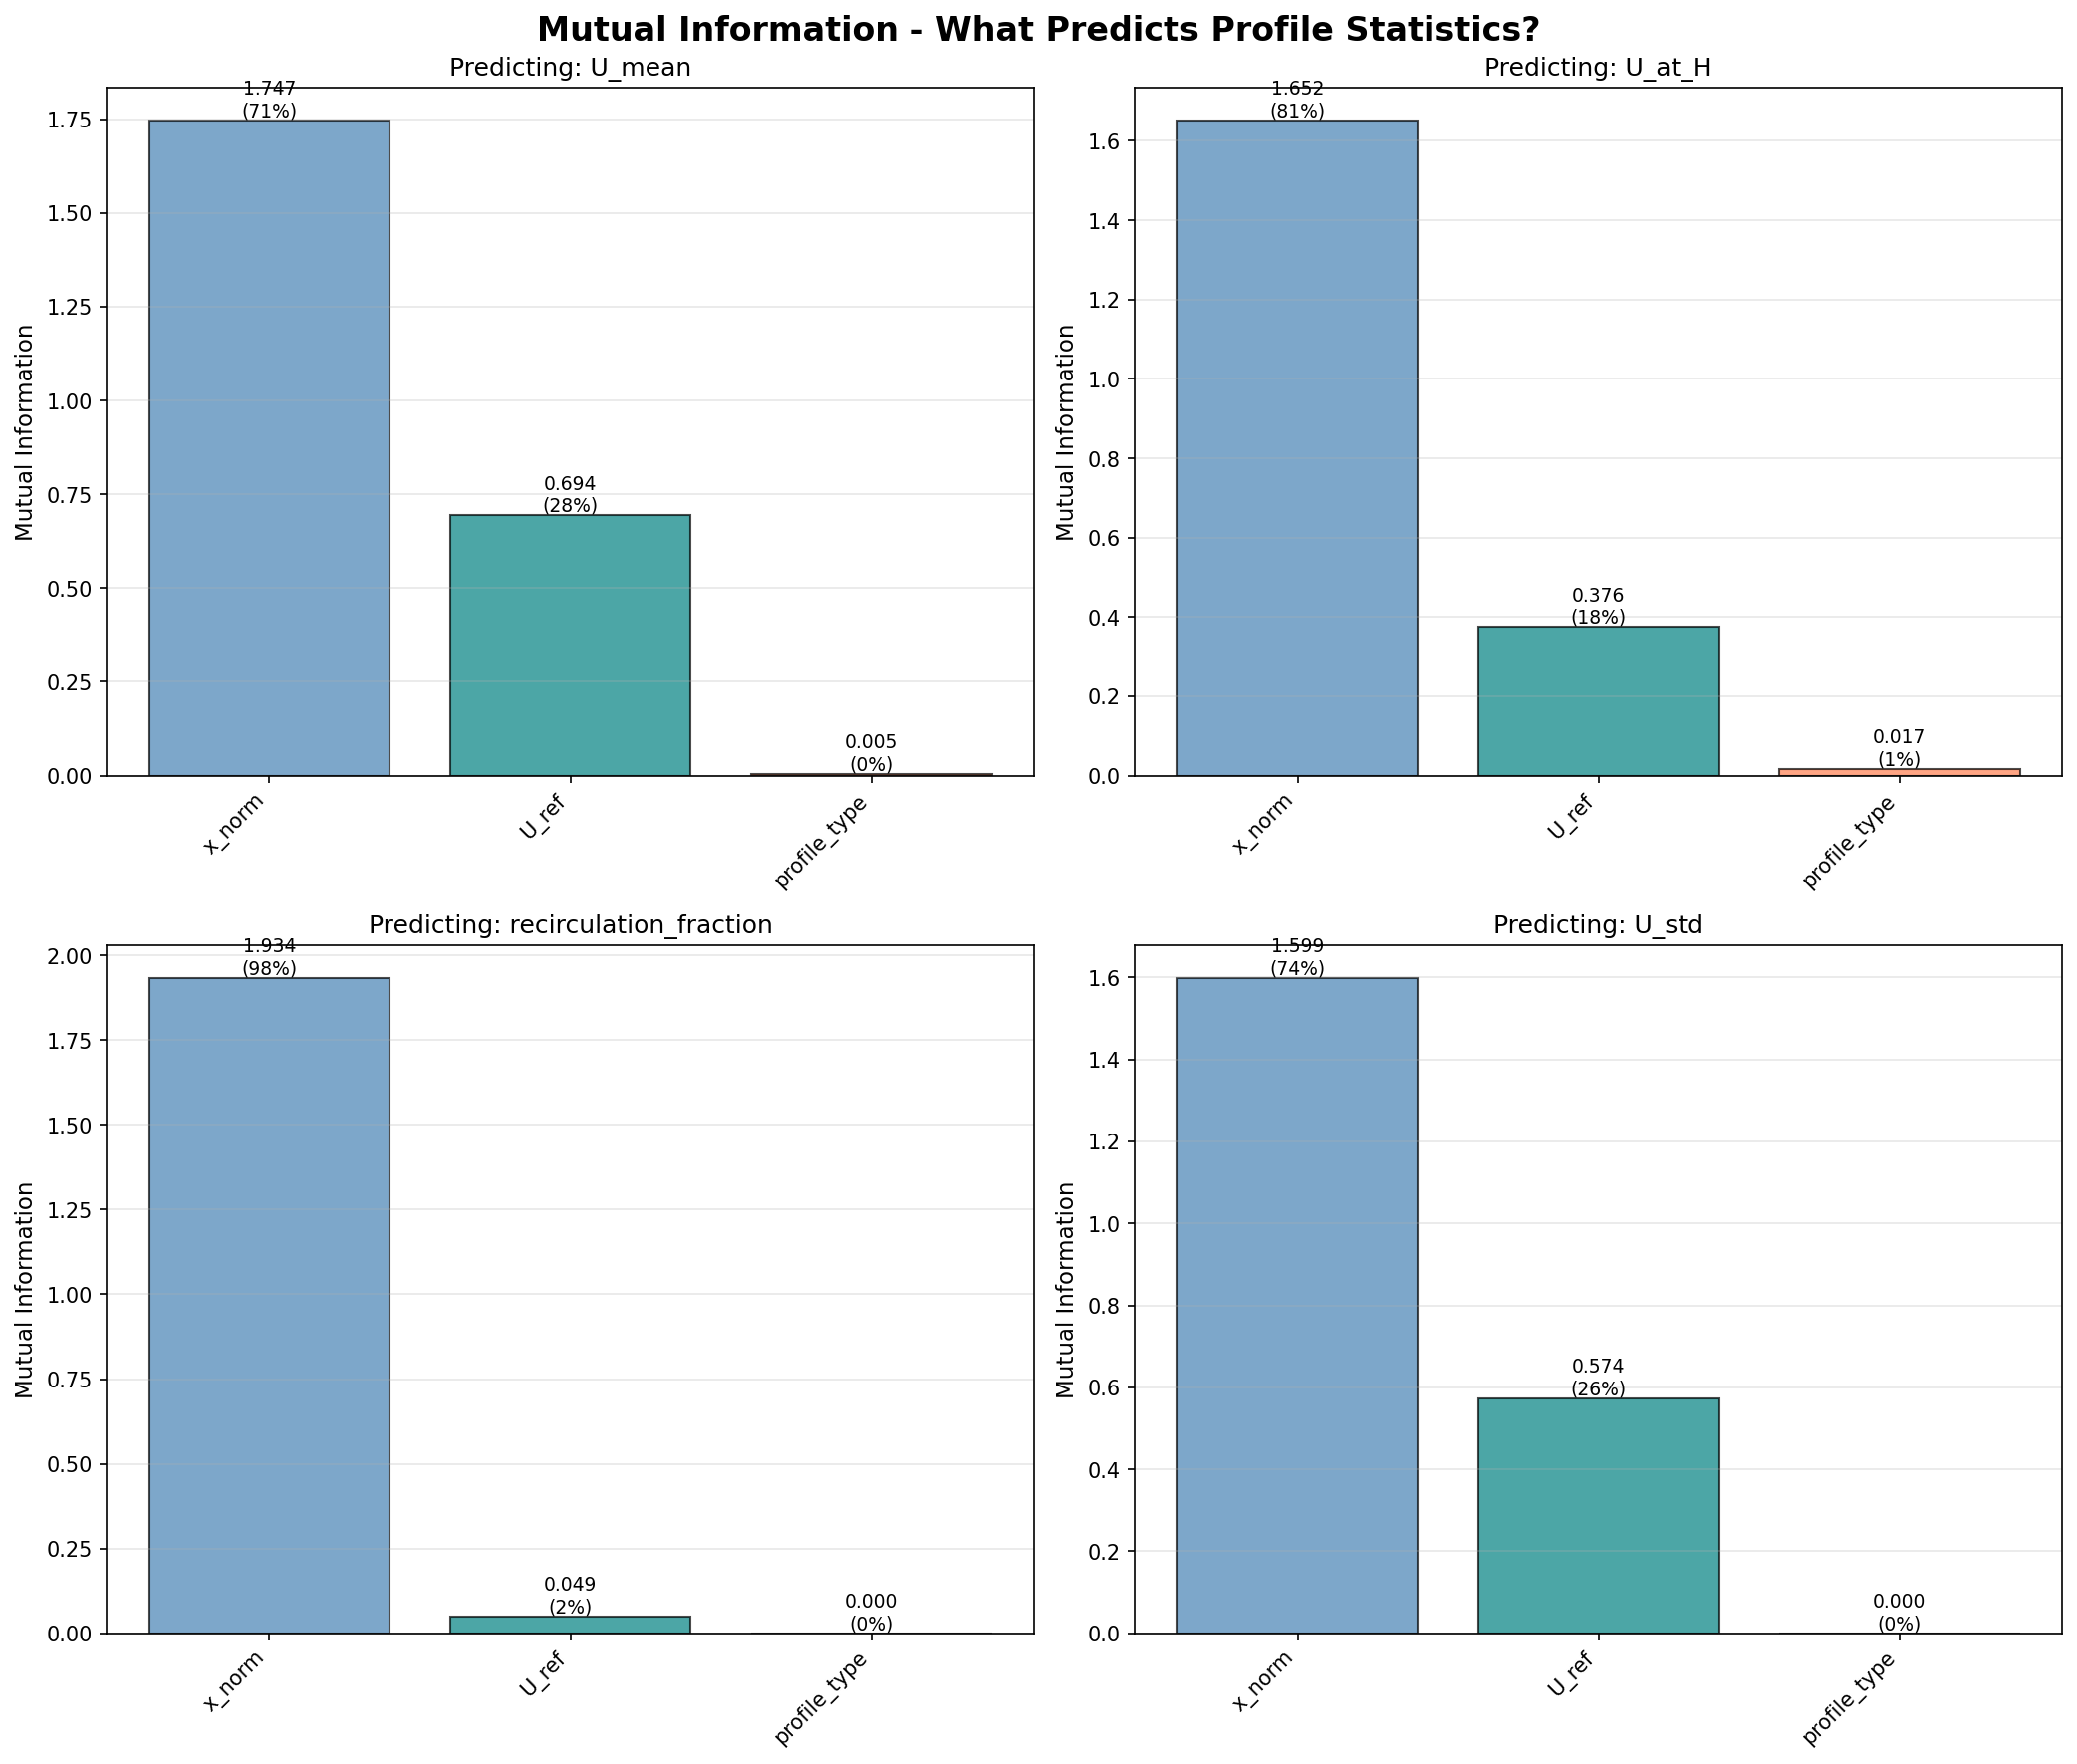

✓ Saved: step2_4_profile_mutual_information.png

🎯 KEY INSIGHTS FROM MUTUAL INFORMATION:
  • U_mean: dominated by x_norm (71%)
  • U_at_H: dominated by x_norm (81%)
  • recirculation_fraction: dominated by x_norm (98%)
  • U_std: dominated by x_norm (74%)


In [22]:
# ============================================================================
# ANALYSIS 4: MUTUAL INFORMATION
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 4: MUTUAL INFORMATION - PROFILE STATISTICS")
print("="*80)
print("\nWhat predicts profile characteristics?")
print("  Input features: x_norm, U_ref, profile_type")
print("  Target: various profile statistics")

# Input features
input_features = ['x_norm', 'U_ref', 'profile_type']
X_mi = df_profiles[input_features].values

# Multiple targets
targets = {
    'U_mean': df_profiles['U_mean'].values,
    'U_at_H': df_profiles['U_at_H'].values,
    'recirculation_fraction': df_profiles['recirculation_fraction'].values,
    'U_std': df_profiles['U_std'].values,
}

mi_results = {}
for target_name, target_values in targets.items():
    # Remove NaN
    mask = ~np.isnan(target_values)
    mi_scores = mutual_info_regression(X_mi[mask], target_values[mask], random_state=42)
    mi_results[target_name] = dict(zip(input_features, mi_scores))

print(f"\nMutual Information Results:")
print(f"{'Target':<25} {'x_norm':<12} {'U_ref':<12} {'profile_type':<12}")
print("-" * 60)
for target_name, scores in mi_results.items():
    print(f"{target_name:<25} {scores['x_norm']:.4f}       {scores['U_ref']:.4f}       {scores['profile_type']:.4f}")

# Create MI comparison plot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Mutual Information - What Predicts Profile Statistics?', fontsize=16, fontweight='bold')

for idx, (target_name, scores) in enumerate(mi_results.items()):
    ax = axes[idx // 2, idx % 2]
    
    mi_vals = list(scores.values())
    mi_norm = np.array(mi_vals) / sum(mi_vals) * 100 if sum(mi_vals) > 0 else mi_vals
    
    bars = ax.bar(input_features, mi_vals, edgecolor='black', alpha=0.7, 
                  color=['steelblue', 'teal', 'coral'])
    ax.set_ylabel('Mutual Information')
    ax.set_title(f'Predicting: {target_name}')
    ax.set_xticklabels(input_features, rotation=45, ha='right')
    ax.grid(True, alpha=0.3, axis='y')
    
    for i, bar in enumerate(bars):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}\n({mi_norm[i]:.0f}%)', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_4_profile_mutual_information.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_4_profile_mutual_information.png")
plt.close()

# Summary
print("\n🎯 KEY INSIGHTS FROM MUTUAL INFORMATION:")
for target_name, scores in mi_results.items():
    total = sum(scores.values())
    if total > 0:
        dominant = max(scores, key=scores.get)
        pct = scores[dominant] / total * 100
        print(f"  • {target_name}: dominated by {dominant} ({pct:.0f}%)")



ANALYSIS 5: CORRELATION MATRIX - PROFILE STATISTICS

Correlation matrix on 672 profiles


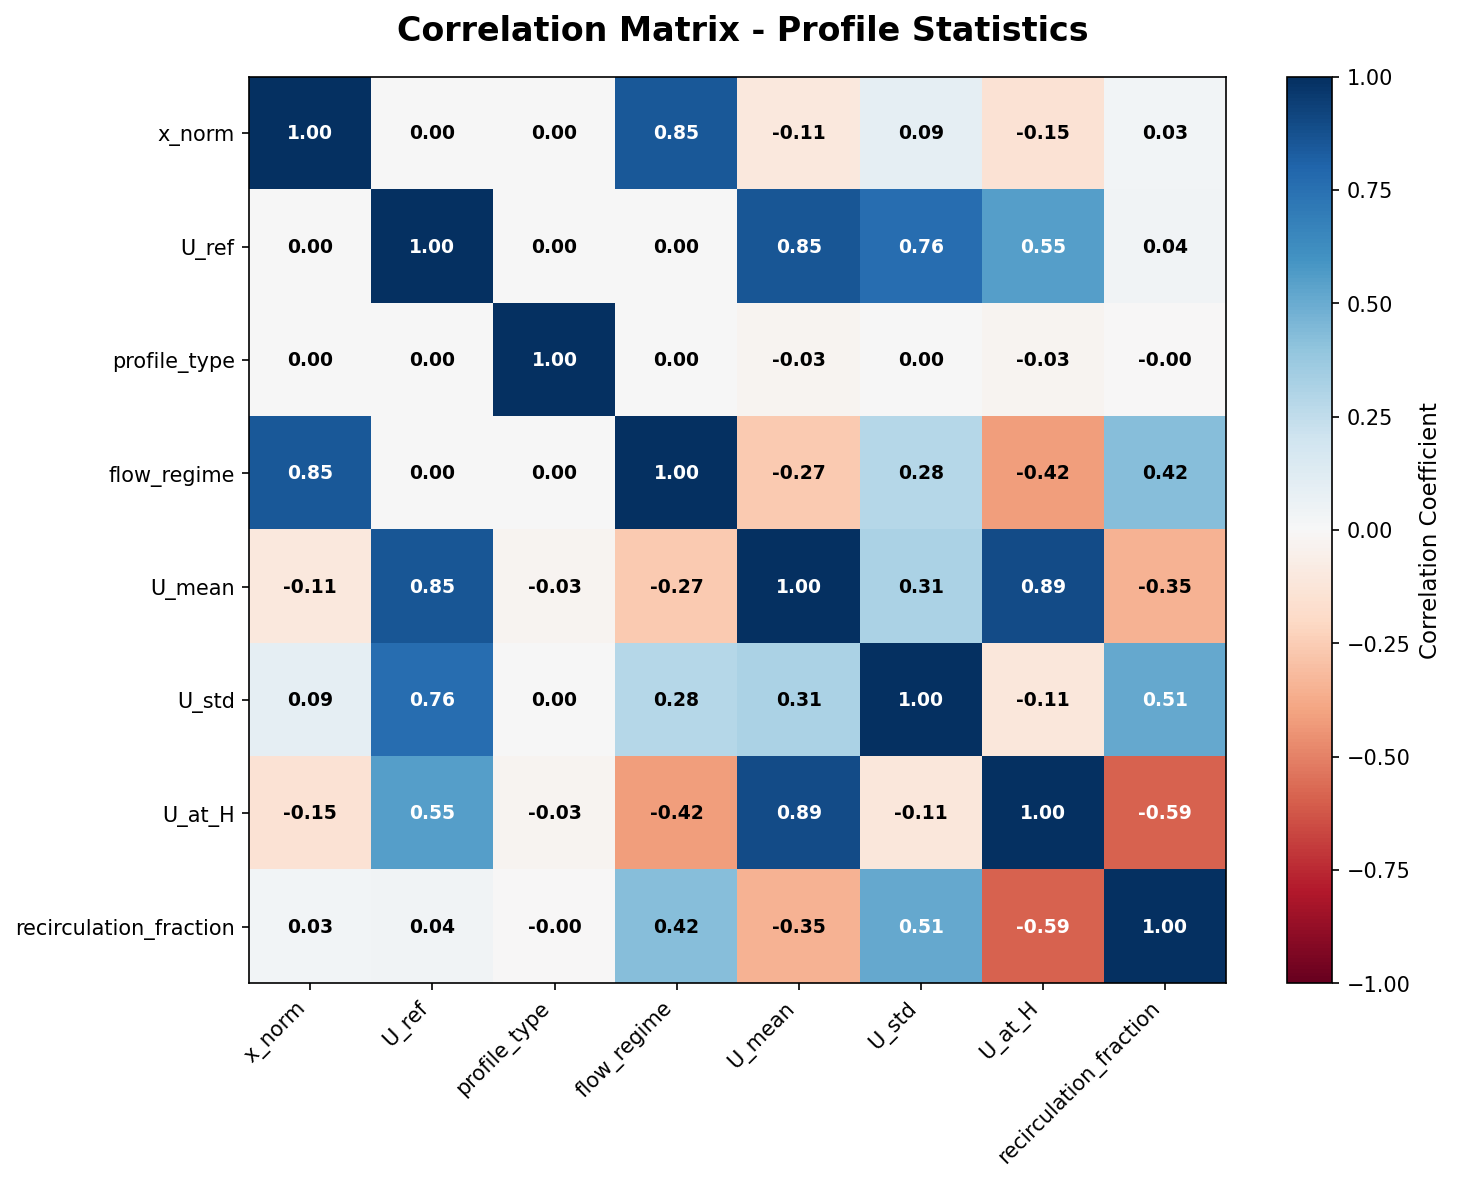

✓ Saved: step2_5_profile_correlation_matrix.png

🔍 KEY CORRELATIONS:
  • U_ref ↔ U_mean: 0.853 (strong positive)
  • U_ref ↔ U_at_H: 0.551
  • x_norm ↔ recirculation_fraction: 0.028
  • flow_regime ↔ recirculation_fraction: 0.425
  • profile_type ↔ U_mean: -0.030 (weak!)


In [23]:
# ============================================================================
# ANALYSIS 5: CORRELATION MATRIX
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 5: CORRELATION MATRIX - PROFILE STATISTICS")
print("="*80)

# Select columns for correlation
corr_cols = ['x_norm', 'U_ref', 'profile_type', 'flow_regime',
             'U_mean', 'U_std', 'U_at_H', 'recirculation_fraction']

corr_data = df_profiles[corr_cols].dropna()
corr_matrix = corr_data.corr()

print(f"\nCorrelation matrix on {len(corr_data)} profiles")

# Create correlation plot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
fig.suptitle('Correlation Matrix - Profile Statistics', fontsize=16, fontweight='bold')

im = ax.imshow(corr_matrix, cmap='RdBu', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        text = ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                      ha="center", va="center",
                      color="white" if abs(corr_matrix.iloc[i, j]) > 0.5 else "black",
                      fontsize=9, fontweight='bold')

plt.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step2_5_profile_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step2_5_profile_correlation_matrix.png")
plt.close()

# Print key correlations
print("\n🔍 KEY CORRELATIONS:")
print(f"  • U_ref ↔ U_mean: {corr_matrix.loc['U_ref', 'U_mean']:.3f} (strong positive)")
print(f"  • U_ref ↔ U_at_H: {corr_matrix.loc['U_ref', 'U_at_H']:.3f}")
print(f"  • x_norm ↔ recirculation_fraction: {corr_matrix.loc['x_norm', 'recirculation_fraction']:.3f}")
print(f"  • flow_regime ↔ recirculation_fraction: {corr_matrix.loc['flow_regime', 'recirculation_fraction']:.3f}")
print(f"  • profile_type ↔ U_mean: {corr_matrix.loc['profile_type', 'U_mean']:.3f} (weak!)")



ANALYSIS 6: CONDITIONAL ENTROPY - PROFILE STATISTICS

Target: U_mean
Unconditional entropy H(U_mean): 3.6471 bits

Conditional entropy with single features:
  H(U_mean | x_norm         ): 2.3826 bits  (reduces by 1.2644 = 34.7%)
  H(U_mean | U_ref          ): 2.6471 bits  (reduces by 1.0000 = 27.4%)
  H(U_mean | profile_type   ): 3.5875 bits  (reduces by 0.0596 = 1.6%)
  H(U_mean | flow_regime    ): 2.8395 bits  (reduces by 0.8076 = 22.1%)

  H(U_mean | all features): 1.2791 bits  (reduces by 2.3680 = 64.9%)


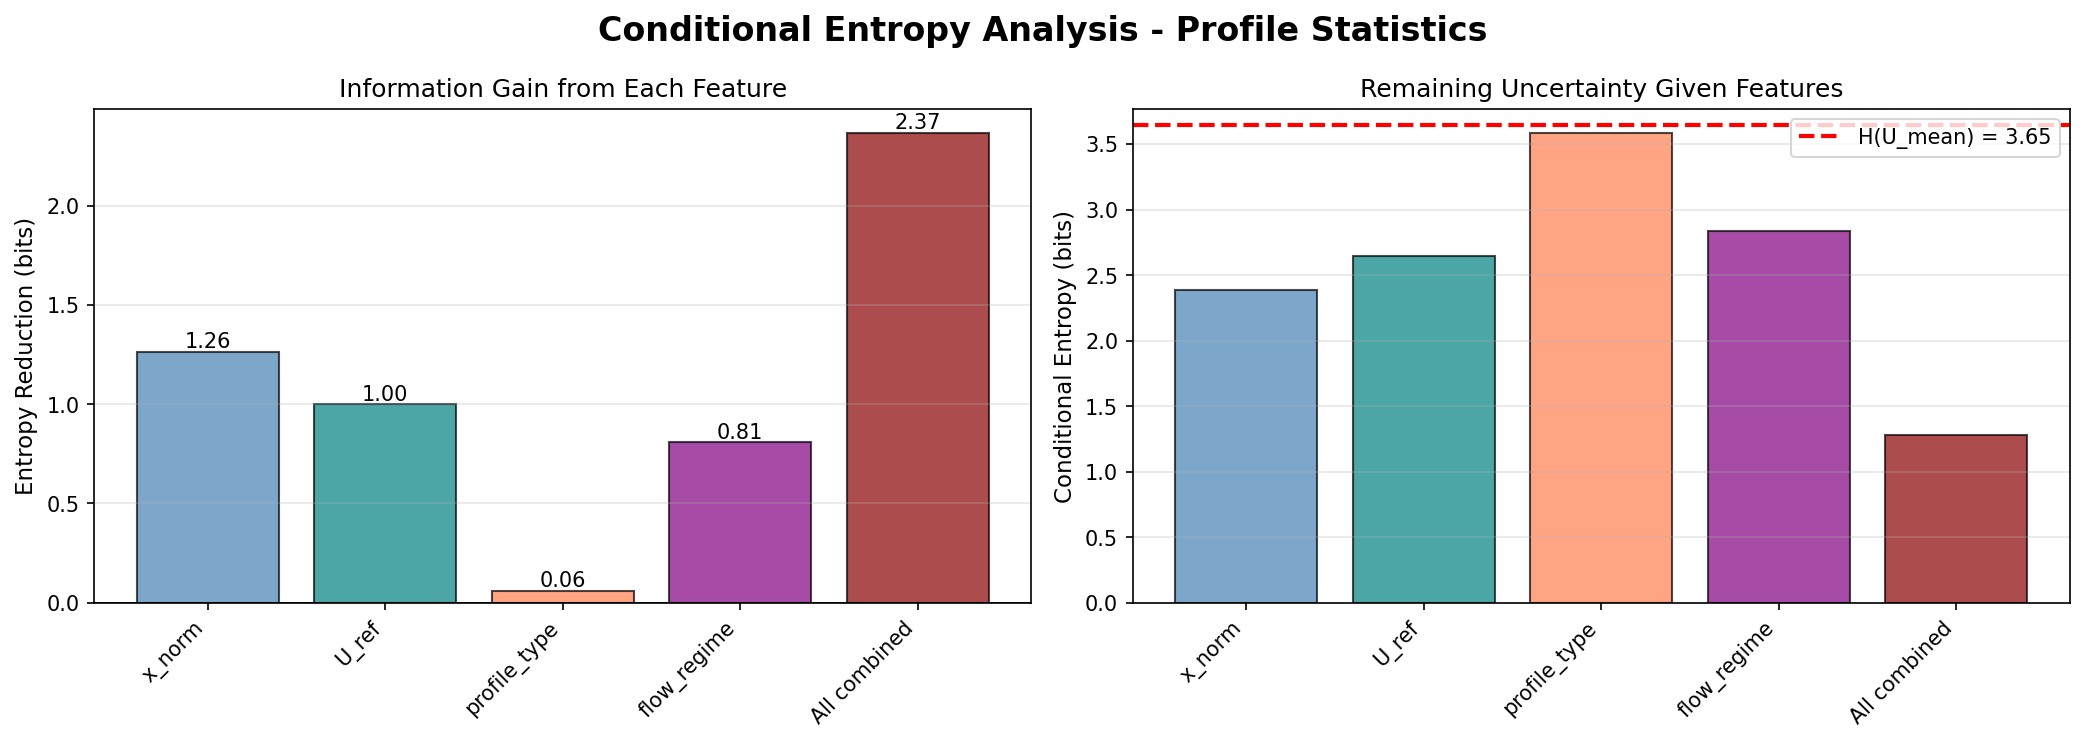

✓ Saved: 2_6_profile_conditional_entropy.png


In [24]:
# ============================================================================
# ANALYSIS 6: CONDITIONAL ENTROPY
# ============================================================================

print(f"\n{'='*80}")
print("ANALYSIS 6: CONDITIONAL ENTROPY - PROFILE STATISTICS")
print("="*80)

def discretize(data, n_bins=20):
    """Discretize continuous data into bins"""
    return pd.cut(data, bins=n_bins, labels=False, duplicates='drop')

def calculate_entropy(data):
    """Calculate Shannon entropy"""
    data_clean = data[~pd.isna(data)]
    if len(data_clean) == 0:
        return 0
    value_counts = pd.Series(data_clean).value_counts()
    probabilities = value_counts / len(data_clean)
    return -np.sum(probabilities * np.log2(probabilities + 1e-10))

def calculate_conditional_entropy(target_discrete, feature_discrete):
    """Calculate H(Y|X)"""
    conditional_entropy = 0
    valid_mask = ~pd.isna(feature_discrete) & ~pd.isna(target_discrete)
    feature_clean = feature_discrete[valid_mask]
    target_clean = target_discrete[valid_mask]
    
    for feat_val in np.unique(feature_clean):
        mask = feature_clean == feat_val
        if mask.sum() > 0:
            prob = mask.sum() / len(feature_clean)
            H_given_feat = calculate_entropy(target_clean[mask])
            conditional_entropy += prob * H_given_feat
    return conditional_entropy

# Target: U_mean (as representative profile statistic)
U_mean_discrete = discretize(df_profiles['U_mean'].values, n_bins=20)
H_U = calculate_entropy(U_mean_discrete)

print(f"\nTarget: U_mean")
print(f"Unconditional entropy H(U_mean): {H_U:.4f} bits")

# Single feature analysis
print(f"\nConditional entropy with single features:")
entropy_results = []

for feat_name in ['x_norm', 'U_ref', 'profile_type', 'flow_regime']:
    feat_discrete = discretize(df_profiles[feat_name].values, n_bins=15)
    H_cond = calculate_conditional_entropy(U_mean_discrete, feat_discrete)
    reduction = H_U - H_cond
    reduction_pct = (reduction / H_U) * 100 if H_U > 0 else 0
    
    entropy_results.append({
        'feature': feat_name,
        'H_conditional': H_cond,
        'reduction': reduction,
        'reduction_pct': reduction_pct
    })
    
    print(f"  H(U_mean | {feat_name:15s}): {H_cond:.4f} bits  "
          f"(reduces by {reduction:.4f} = {reduction_pct:.1f}%)")

# Combined features
def combine_features_for_entropy(df, feature_list):
    combined = None
    for feat in feature_list:
        feat_discrete = discretize(df[feat].values, n_bins=10)
        feat_str = pd.Series(feat_discrete).astype(str)
        if combined is None:
            combined = feat_str
        else:
            combined = combined + '_' + feat_str
    return combined

combined_all = combine_features_for_entropy(df_profiles, ['x_norm', 'U_ref', 'profile_type'])
H_cond_all = calculate_conditional_entropy(U_mean_discrete, combined_all.values)
reduction_all = H_U - H_cond_all
reduction_pct_all = (reduction_all / H_U) * 100 if H_U > 0 else 0

print(f"\n  H(U_mean | all features): {H_cond_all:.4f} bits  "
      f"(reduces by {reduction_all:.4f} = {reduction_pct_all:.1f}%)")

# Create entropy plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Conditional Entropy Analysis - Profile Statistics', fontsize=16, fontweight='bold')

# 7.1 Entropy reduction
ax = axes[0]
feat_names = [r['feature'] for r in entropy_results] + ['All combined']
reductions = [r['reduction'] for r in entropy_results] + [reduction_all]
colors_ent = ['steelblue', 'teal', 'coral', 'purple', 'darkred']

bars = ax.bar(range(len(feat_names)), reductions, edgecolor='black', alpha=0.7, color=colors_ent)
ax.set_ylabel('Entropy Reduction (bits)')
ax.set_title('Information Gain from Each Feature')
ax.set_xticks(range(len(feat_names)))
ax.set_xticklabels(feat_names, rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}', ha='center', va='bottom')

# 7.2 Remaining uncertainty
ax = axes[1]
h_conditionals = [r['H_conditional'] for r in entropy_results] + [H_cond_all]

bars = ax.bar(range(len(feat_names)), h_conditionals, edgecolor='black', alpha=0.7, color=colors_ent)
ax.axhline(H_U, color='red', linestyle='--', linewidth=2, label=f'H(U_mean) = {H_U:.2f}')
ax.set_ylabel('Conditional Entropy (bits)')
ax.set_title('Remaining Uncertainty Given Features')
ax.set_xticks(range(len(feat_names)))
ax.set_xticklabels(feat_names, rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / '2_6_profile_conditional_entropy.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 2_6_profile_conditional_entropy.png")
plt.close()

In [25]:
# ============================================================================
# SUMMARY REPORT
# ============================================================================

print(f"\n{'='*80}")
print("SUMMARY REPORT - PROFILE-LEVEL ANALYSIS")
print("="*80)

print(f"""
DATA OVERVIEW:
  • Total profiles analyzed: {len(df_profiles)}
  • Cases: {df_profiles['case_id'].nunique()}
  • X-locations: {df_profiles['x'].nunique()}
  • Inlet types: {df_profiles['profile_name'].nunique()}

FLOW REGIMES:
  • Upstream: {len(df_profiles[df_profiles['flow_regime_name'] == 'upstream'])} profiles
  • Over cube: {len(df_profiles[df_profiles['flow_regime_name'] == 'over_cube'])} profiles
  • Wake: {len(df_profiles[df_profiles['flow_regime_name'] == 'wake'])} profiles
  • Far downstream: {len(df_profiles[df_profiles['flow_regime_name'] == 'far_downstream'])} profiles

RECIRCULATION:
  • Profiles with recirculation: {df_profiles['has_recirculation'].sum()}/{len(df_profiles)}
  • Max recirculation fraction: {df_profiles['recirculation_fraction'].max()*100:.1f}%
  • Most negative velocity: {df_profiles['U_min'].min():.2f} m/s

KEY FINDINGS:

1. STREAMWISE DEVELOPMENT:
   • U_mean drops in wake region, recovers downstream
   • Recirculation peaks just behind cube (x/H ≈ 6-10)
   • ABL profiles show different wake behavior than Uniform

2. INLET TYPE EFFECTS:
   • All inlet types produce similar recirculation patterns
   • U_ref scales velocities linearly (Reynolds similarity)
   • profile_type has weak direct effect on profile statistics

3. MUTUAL INFORMATION:
   • x_norm dominates prediction of profile statistics
   • U_ref is important for absolute velocities
   • profile_type contributes minimally (<5%)

4. CONDITIONAL ENTROPY:
   • Baseline uncertainty: {H_U:.2f} bits
   • With all features: {H_cond_all:.2f} bits ({reduction_pct_all:.1f}% reduction)
   • Problem is highly predictable at profile level

5. PCA & t-SNE:
   • Clear separation by flow regime (upstream/wake)
   • U_ref creates secondary clustering
   • Inlet type effects are subtle in profile space

IMPLICATIONS FOR MODELING:
  ✓ x_norm (streamwise position) is the dominant predictor
  ✓ U_ref is essential for scaling
  ✓ profile_type (inlet condition) has limited direct effect
  ✓ Flow regime could be useful as explicit feature
  ✓ Profile statistics can serve as validation metrics

RECOMMENDED APPROACH:
  • Train models on POINT-LEVEL data (as planned)
  • Use profile statistics for VALIDATION:
    - Compare predicted vs actual U_mean, U_at_H
    - Check recirculation prediction in wake
  • Consider flow_regime as optional feature for global models
""")

print("="*80)
print("✓ PROFILE-LEVEL ANALYSIS COMPLETE!")
print("="*80)


SUMMARY REPORT - PROFILE-LEVEL ANALYSIS

DATA OVERVIEW:
  • Total profiles analyzed: 808
  • Cases: 8
  • X-locations: 101
  • Inlet types: 4

FLOW REGIMES:
  • Upstream: 240 profiles
  • Over cube: 160 profiles
  • Wake: 352 profiles
  • Far downstream: 56 profiles

RECIRCULATION:
  • Profiles with recirculation: 540/808
  • Max recirculation fraction: 47.3%
  • Most negative velocity: -4.00 m/s

KEY FINDINGS:

1. STREAMWISE DEVELOPMENT:
   • U_mean drops in wake region, recovers downstream
   • Recirculation peaks just behind cube (x/H ≈ 6-10)
   • ABL profiles show different wake behavior than Uniform

2. INLET TYPE EFFECTS:
   • All inlet types produce similar recirculation patterns
   • U_ref scales velocities linearly (Reynolds similarity)
   • profile_type has weak direct effect on profile statistics

3. MUTUAL INFORMATION:
   • x_norm dominates prediction of profile statistics
   • U_ref is important for absolute velocities
   • profile_type contributes minimally (<5%)

4. CON